# matplotlib の高度な使い方

In [1]:
import numpy as np
import helper.matplotlib
from matplotlib import pyplot as plt

## この章で学ぶこと

ここまでの章で、よく使う描き方は分かったはずです。この章では、座標の変換と注釈を中心に、図を思いどおりに仕上げる方法を説明します。

* 4 つの座標系と変換
* 塗りつぶしと矢印付きの注釈
* 変換の部品(`transData` の中身)
* 影を付ける、文字を置く
* AGG で直接描く、アニメーション

## 座標変換と注釈

1 つの図には、いくつもの座標系と変換が関わっています。それぞれの意味が分かると、文字や矢印の位置を自由に決められます。この節では、注釈を例に座標系と変換を説明します。

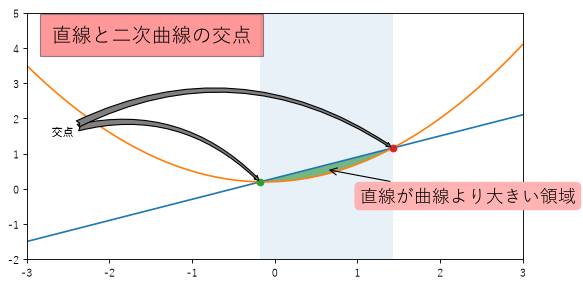

In [2]:
def func1(x):  #❶
    return 0.6 * x + 0.3


def func2(x):  #❶
    return 0.4 * x * x + 0.1 * x + 0.2


def find_curve_intersects(x, y1, y2):
    d = y1 - y2
    idx = np.where(d[:-1] * d[1:] <= 0)[0]
    x1, x2 = x[idx], x[idx + 1]
    d1, d2 = d[idx], d[idx + 1]
    return -d1 * (x2 - x1) / (d2 - d1) + x1


x = np.linspace(-3, 3, 100)  #❷
f1 = func1(x)
f2 = func2(x)
fig, ax = plt.subplots(figsize=(8, 4), dpi=80)
ax.plot(x, f1)
ax.plot(x, f2)

x1, x2 = find_curve_intersects(x, f1, f2)  #❸
ax.plot(x1, func1(x1), "o")
ax.plot(x2, func1(x2), "o")

ax.fill_between(x, f1, f2, where=f1 > f2, facecolor="green", alpha=0.5)  #❹

from matplotlib import transforms

trans = transforms.blended_transform_factory(ax.transData, ax.transAxes)
ax.fill_between([x1, x2], 0, 1, transform=trans, alpha=0.1)  #❺

a = ax.text(
    0.05,
    0.95,
    "直線と二次曲線の交点",  #❻
    transform=ax.transAxes,
    verticalalignment="top",
    fontsize=18,
    bbox={"facecolor": "red", "alpha": 0.4, "pad": 10},
)

arrow = {
    "arrowstyle": "fancy,tail_width=0.6",
    "facecolor": "gray",
    "connectionstyle": "arc3,rad=-0.3",
}

ax.annotate(
    "交点",  #❼
    xy=(x1, func1(x1)),
    xycoords="data",
    xytext=(0.05, 0.5),
    textcoords="axes fraction",
    arrowprops=arrow,
)

ax.annotate(
    "交点",  #❼
    xy=(x2, func1(x2)),
    xycoords="data",
    xytext=(0.05, 0.5),
    textcoords="axes fraction",
    arrowprops=arrow,
)

xm = (x1 + x2) / 2
ym = (func1(xm) - func2(xm)) / 2 + func2(xm)
o = ax.annotate(
    "直線が曲線より大きい領域",  #❼
    xy=(xm, ym),
    xycoords="data",
    xytext=(30, -30),
    textcoords="offset points",
    bbox={"boxstyle": "round", "facecolor": (1.0, 0.7, 0.7), "edgecolor": "none"},
    fontsize=16,
    arrowprops={"arrowstyle": "->"},
)

ax.set_xlim(-3, 3)
ax.set_ylim(-2, 5);

この図では、次の注釈を付けています。

* 直線と曲線の交点を、2 つの小さな点で示す。
* 2 つの交点の間で、2 本の線の間を塗る。
* 2 つの交点の間を示すために、高さがサブプロット全体で、左右の辺が交点を通る長方形を描く。
* 左上に説明の文を置く。
* 交点と塗った部分に、矢印付きの注釈を付ける。

まず ❶ 直線と 2 次曲線の関数 `func1`、`func2` を定義します。❷ 区間 `(-3, 3)` で計算し、`plot()` で描きます。

❸ 交点に印を付けるために、`find_curve_intersects()` で 2 本の曲線の交点の x 座標 `x1`、`x2` を求めます。交点の点は `plot()` で描きます。x と y に 1 つの数を渡し、書式を `'o'` にします。

:::{admonition} 2 本の曲線の交点を求める
:class: note
2 本の曲線の y が同じ x の並びで計算されていれば、交点は簡単に求まります。差 `d = y1 - y2` を計算し、符号が変わる隣り合う 2 点 `idx`、`idx + 1` を探します。線分 `(x[idx], d[idx])`〜`(x[idx+1], d[idx+1])` と x 軸の交点が、曲線の交点の x 座標 `xc` です。y は `np.interp(xc, x, y1)` で補間して求めます。
:::

❹ `fill_between()` で、x 軸では 2 つの交点の間、y 軸では 2 本の曲線の間を塗ります。色と透明度は `facecolor` と `alpha` で決めます。呼び方は次のとおりです。

```python
fill_between(x, y1, y2=0, where=None)
```

`x` は長さ `N` の配列で、`y1` と `y2` は長さ `N` の配列か 1 つの数です。数なら、すべて同じ値の配列と見なします。`where` が `None` なら全部を塗り、真偽の配列なら `True` のところだけを塗ります。ここでは `where = f1 > f2` なので、直線が曲線より上にある部分だけを塗ります。

❺ 2 つの交点の間の長方形を描きます。❻ `text()` で説明の文を置きます。❼ 最後に `annotate()` で矢印付きの注釈を付けます。

このプログラムを本当に理解するには、まず座標変換の仕組みを知る必要があります。

### 4 つの座標系

1 つの図には、4 つの座標系があります。

* データ座標系：データの空間での位置。この図なら x が `(-3, 3)`、y が `(-2, 5)`。
* サブプロット座標系：サブプロットの中の位置。左下が `(0, 0)`、右上が `(1, 1)`。
* 図座標系：図全体の中の位置。サブプロットのまわりに余白があるので、図全体を表す座標が要る。左下が `(0, 0)`、右上が `(1, 1)`。
* ウィンドウ座標系：描画ウィンドウの中のピクセル。左下が `(0, 0)`、右上が `(幅, 高さ)`。タイトルバーなどは含まない。

`Axes` の `transData` がデータ座標の変換、`transAxes` がサブプロット座標の変換です。`Figure` の `transFigure` が図座標の変換です。

変換オブジェクトの `transform()` で、その座標をウィンドウ座標に変えられます。次のプログラムは、データ座標の `(-3, -2)` と `(3, 5)` をウィンドウ座標にします。

In [3]:
print(type(ax.transData))
ax.transData.transform([(-3, -2), (3, 5)])

<class 'matplotlib.transforms.CompositeGenericTransform'>


array([[ 80. ,  35.2],
       [576. , 281.6]])

次のプログラムは、サブプロット座標の `(0, 0)` と `(1, 1)` をウィンドウ座標にします。結果は上と同じです。サブプロットの左下と、データ座標の `(-3, -2)` が、画面では同じ点だということです。

In [4]:
ax.transAxes.transform([(0, 0), (1, 1)])

array([[ 80. ,  35.2],
       [576. , 281.6]])

最後に、図座標の `(0, 0)` と `(1, 1)` をウィンドウ座標にします。描画の領域が 640×320 ピクセルだと分かります。

In [5]:
fig.transFigure.transform([(0, 0), (1, 1)])

array([[  0.,   0.],
       [640., 320.]])

`inverted()` で、逆の変換が取れます。次のプログラムは、ウィンドウ座標の `(320, 160)` をデータ座標にします。

In [6]:
inv = ax.transData.inverted()
print(type(inv))
inv.transform((320, 160))

<class 'matplotlib.transforms.CompositeGenericTransform'>


array([-0.09677419,  1.54545455])

図を見てください。サブプロットの余白は上下左右で違うので、描画の中心 `(320, 160)` は、データの中心 `(0, 1.5)` ではありません。

`set_xlim()` で表示の範囲を変えると、データ座標の変換も変わります。

In [7]:
print(ax.set_xlim(-3, 2))  # X軸の範囲を-3から2に設定
print(ax.transData.transform((3, 5)))  # データ座標変換オブジェクトが変更されました

(-3.0, 2.0)
[675.2 281.6]


上の図で、長方形を描いた部分を見てみます。

```python
from matplotlib import transforms
trans = transforms.blended_transform_factory(ax.transData, ax.transAxes)
ax.fill_between([x1, x2], 0, 1, transform=trans, alpha=0.1)
```

左右の辺が交点を通るので、x はデータ座標の `x1`、`x2` を使います。高さがサブプロット全体なので、y はサブプロット座標の 0 と 1 を使います。

:::{tip}
垂直・水平の帯なら、`axvspan()` と `axhspan()` で簡単に描けます。
:::

この混合の座標系は、`blended_transform_factory()` で作ります。2 つの引数はどちらも変換で、1 つ目から x の変換、2 つ目から y の変換を取ります。返る `trans` は、x がデータ座標、y がサブプロット座標です。これを `fill_between()` の `transform` に渡すと、左右の辺が交点を通り、上下がサブプロットの枠に合います。

### 変換のパイプライン

座標系を移すには、いくつもの段階があります。データ座標は直交座標とは限らず、極座標や対数座標のこともあります。なので、変換は単純な 2 次元のアフィン変換ではありません。まず一番単純な `transFigure` から、matplotlib の変換の流れを見ます。

この本の `GraphvizMPLTransform` を使うと、変換の関係を図にできます。次の図は `fig.transFigure` の中身です。

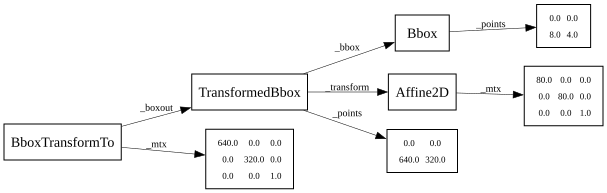

In [8]:
from helper.dot import GraphvizMPLTransform
import graphviz

graphviz.Source(GraphvizMPLTransform.graphviz(fig.transFigure))

この変換は `BboxTransformTo` で、その中に `TransformedBbox` が入っています。`TransformedBbox` には `Bbox` と `Affine2D` があります。

* `Bbox`：長方形 `[[x0, y0], [x1, y1]]`。この例では `(0, 0)` と `(8, 4)` で、図のインチの大きさです(`figsize`)。
* `Affine2D`：2 次元のアフィン変換で、行列です。対角以外が 0 なので、拡大だけを行い、`(x, y)` を `(80*x, 80*y)` にします。

:::{admonition} アフィン変換
:class: note
2 次元のアフィン変換の行列は $3 \times 3$ で、同次座標を使います。点 `(x, y)` を `(x, y, 1)` で表し、行列を掛けます。最下行は常に `(0, 0, 1)` なので、$2 \times 3$ で書くこともあります。

$$\begin{pmatrix} x' \\ y' \\ 1 \end{pmatrix} = \begin{pmatrix} a_{00} & a_{01} & b_0 \\ a_{10} & a_{11} & b_1 \\ 0 & 0 & 1 \end{pmatrix} \begin{pmatrix} x \\ y \\ 1 \end{pmatrix}$$
:::

* `TransformedBbox`：長方形をアフィン変換したあとの長方形。この例では頂点が `(0, 0)` と `(640, 320)` です。計算を繰り返さないように、`_points` に頂点を覚えています。これはピクセルの大きさなので、行列の 80 は `Figure` の `dpi` です。
* `BboxTransformTo`：単位の長方形から、指定した長方形への変換。この例では `(0, 0)-(1, 1)` を `(0, 0)-(640, 320)` にするので、図座標をウィンドウ座標にできます。行列は `_mtx` に覚えています。

`fig.transFigure` のアフィン変換は `fig.dpi_scale_trans` で取れます。

In [9]:
fig.dpi_scale_trans == fig.transFigure._boxout._transform

np.True_

次に、サブプロット座標の変換の中身を見ます。

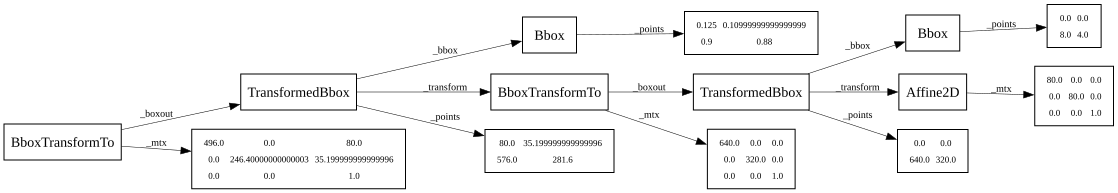

In [10]:
graphviz.Source(GraphvizMPLTransform.graphviz(ax.transAxes))

`ax.transAxes` は `BboxTransformTo` なので、`(0, 0)-(1, 1)` を別の長方形に変えます。その長方形は `TransformedBbox` で、`(0.125, 0.1)-(0.9, 0.9)` を `fig.transFigure` で変換したものです。つまり `transAxes` の中では `transFigure` が使われています。

In [11]:
ax.transAxes._boxout._transform == fig.transFigure

np.True_

この変換のあいだの長方形 `(0.125, 0.11)-(0.9, 0.88)` が、図座標でのサブプロットの位置です。

In [12]:
ax.get_position()

Bbox([[0.125, 0.10999999999999999], [0.9, 0.88]])

サブプロットのウィンドウ座標での長方形は、次のとおりです。

In [13]:
ax.transAxes._boxout.bounds

(np.float64(80.0),
 np.float64(35.199999999999996),
 np.float64(496.0),
 np.float64(246.40000000000003))

つまり `ax.transAxes` は、`(0, 0)-(1, 1)` を `(80.0, 35.2)-(496.0, 246.4)` に変える変換です。

最後に、データ座標の `ax.transData` を見ます。これは `transScale`、`transLimits`、`transAxes` からできているので、まず `transLimits` と `transScale` を見ます。`transLimits` は `BboxTransformFrom` で、指定した長方形を `(0,0)-(1,1)` に変えます。

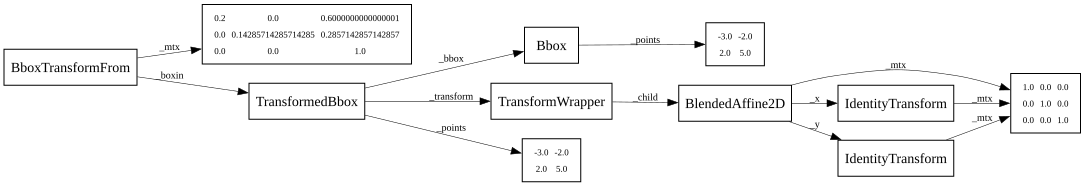

In [14]:
graphviz.Source(GraphvizMPLTransform.graphviz(ax.transLimits))

`transLimits` の元の長方形は `TransformedBbox` で、`(-3, -2)-(2, 5)` を変換したものです。ここでの変換は `TransformWrapper` で、上の図では恒等変換です。なので `transLimits` は、`(-3, -2)-(2, 5)` を `(0, 0)-(1, 1)` に変えることになります。

In [15]:
print(ax.transLimits.transform((-3, -2)))
print(ax.transLimits.transform((2, 5)))

[0. 0.]
[1. 1.]


長方形 `(-3, -2)-(2, 5)` は、軸の表示範囲で決まります。

In [16]:
print(ax.get_xlim())  # X軸の表示範囲を取得
print(ax.get_ylim())  # Y軸の表示範囲を取得

(np.float64(-3.0), np.float64(2.0))
(np.float64(-2.0), np.float64(5.0))


`transLimits` がデータの範囲を単位の長方形にし、`transAxes` がそれをピクセルの長方形にします。合わせると、データ座標がウィンドウ座標になります。2 つの変換は `+` でつなげます。`ax.transLimits + ax.transAxes` は、`transLimits` のあとに `transAxes` を行う意味です。変換は、工場の流れ作業のように座標を順に変えます。次のプログラムで `ax.transData` の結果と比べます。

In [17]:
t = ax.transLimits + ax.transAxes
print(t.transform((0, 0)))
print(ax.transData.transform((0, 0)))

[377.6 105.6]
[377.6 105.6]


軸の縮尺を変えられるように、`transData` には `transScale` も入っています。つまり `transData = transScale + transLimits + transAxes` です。この例の `transScale` は恒等変換なので、`ax.transLimits + ax.transAxes` と `ax.transData` は同じ結果になります。

In [18]:
ax.transScale

`semilogx()`、`semilogy()`、`loglog()` で対数軸の図を描くときや、`set_xscale()`、`set_yscale()` で対数にしたときは、`transScale` は恒等変換ではなくなり、中身は次の図のようになります。

:::{warning}
この例の x の範囲は `(-3, 3)` なので、x 軸を対数にすると、負の値でたくさんエラーが出ます。
:::

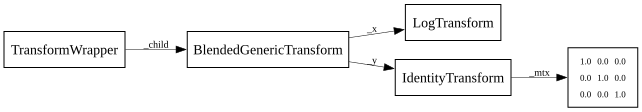

In [19]:
ax.set_xscale("log")  # X軸を対数座標に変更
graphviz.Source(GraphvizMPLTransform.graphviz(ax.transScale))

In [20]:
ax.set_xscale("linear")  # X軸を線形座標に変更

### 影を付ける

前の節の変換を使って、影の付いた曲線を描きます。

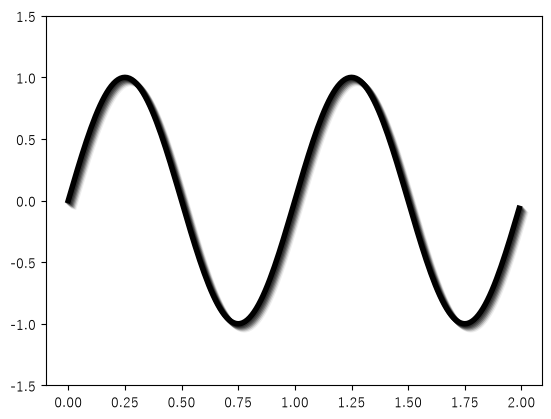

In [21]:
fig, ax = plt.subplots()
x = np.arange(0.0, 2.0, 0.01)
y = np.sin(2 * np.pi * x)

N = 7  # シャドウの本数
for i in range(N, 0, -1):
    offset = transforms.ScaledTranslation(i, -i, transforms.IdentityTransform())  #❶
    shadow_trans = plt.gca().transData + offset  #❷
    ax.plot(
        x,
        y,
        linewidth=4,
        color="black",
        transform=shadow_trans,  #❸
        alpha=(N - i) / 2.0 / N,
    )

ax.plot(x, y, linewidth=4, color="black")
ax.set_ylim((-1.5, 1.5));

透明度と位置を少しずつ変えた曲線を N 本描き、そのあとに本当の曲線を描くと、影に見えます。

❶ `offset` は `ScaledTranslation` で、最初の 2 つの引数が x と y のずれ、3 つ目が変換です。ここでは 3 つ目が恒等変換なので、x に `i`、y から `i` を引くだけの移動になります。

次は `i` が 1 のときの `offset` です。

In [22]:
offset.transform((0, 0))  # (0,0)を(1,-1)に変換

array([ 1., -1.])

❷ 影の曲線の変換は `shadow_trans` で、データ座標の変換 `transData` と `offset` からできています。

In [23]:
print(ax.transData.transform((0, 0)))  # (0,0)をデータ座標変換
print(shadow_trans.transform((0, 0)))  # (0,0)をデータ座標変換とオフセット変換

[102.54545455 237.6       ]
[103.54545455 236.6       ]


❸ 最後に `shadow_trans` を `plot()` の `transform` に渡します。データ座標からウィンドウ座標に変えたあとでずらすので、拡大しても影の見え方は変わりません。

### 注釈を付ける

`pyplot` には、文字を置く関数が 2 つあります。`text()` は今の `Axes`、`figtext()` は今の `Figure` の `text()` を呼びます。`text()` はデータ座標、`figtext()` は図座標に置きます。`transform` で座標系を変えられます。次のプログラムは、3 つの座標系に文字を置きます。

Text(0.1, 0.92, 'チャート座標系のテキスト')

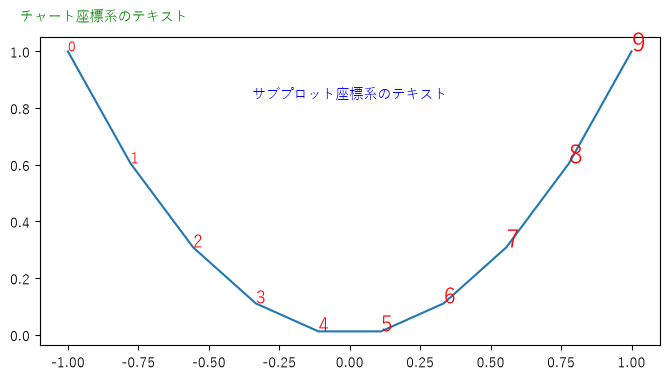

In [24]:
x = np.linspace(-1, 1, 10)
y = x**2

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, y)

for i, (_x, _y) in enumerate(zip(x, y)):
    ax.text(_x, _y, str(i), color="red", fontsize=i + 10)  #❶

ax.text(
    0.5,
    0.8,
    "サブプロット座標系のテキスト",
    color="blue",
    ha="center",
    transform=ax.transAxes,
)  #❷

plt.figtext(0.1, 0.92, "チャート座標系のテキスト", color="green")  #❸;

❶ `transform` を渡していないので、`text()` はデータ座標に置きます。`fontsize` で大きさを変えます。❷ `transform=ax.transAxes` にすると、サブプロット座標に置きます。`ha` は水平方向のそろえ方で、`'center'` なら `(0.5, 0.8)` が文字の中心です。❸ `figtext()` は図座標に置きます。

ズームや移動をすると、データ座標の文字は曲線に付いて動き、ほかの 2 つは動きません。サブプロットの余白を変えると、サブプロット座標の文字はサブプロットの中心に合わせて動きます。図座標の文字は、ウィンドウの大きさを変えたときだけ動きます。

文字の関数には、文字や枠の見た目を決める引数がたくさんあります。詳しくは公式の説明を見てください。

`annotate()` で、矢印付きの注釈を描きます。呼び方は次のとおりです。

```python
annotate(s, xy, xytext=None, xycoords='data', textcoords='data', arrowprops=None, ...)
```

`s` が注釈の文、`xy` が矢印の先の座標、`xytext` が文の座標です。`xycoords` と `textcoords` で、それぞれの座標系を決めます。

2 つの座標は別の座標系にできます。指定できる値は次のとおりです。

| 値  | 意味  |
|:--|:--|
| `figure points`  | 図の左下から、ポイント単位 |
| `figure pixels`  | 図の左下から、ピクセル単位 |
| `figure fraction`  | 図座標 |
| `axes points`  | サブプロットの左下から、ポイント単位 |
| `axes pixels`  | サブプロットの左下から、ピクセル単位 |
| `axes fraction`  | サブプロット座標 |
| `data`  | データ座標 |
| `offset points`  | 指定した点から、ポイント単位でずらす |
| `offset pixels`  | 指定した点から、ピクセル単位でずらす |

## テクニック

最後に、いくつか特別な使い方を紹介します。

### agg バックエンドで描く

matplotlib の図がきれいなのは、C++ で書かれたアンチエイリアスの描画ライブラリ Anti-Grain Geometry(AGG)を使っているからです。2 次元の図形だけを描きたいときは、メモリの上で描いて NumPy 配列にできます。

次のコードは `RendererAgg`(画布)を 250×250 ピクセルで作ります。3 番目の引数は dpi で、画布の大きさには影響しません。`buffer_rgba()` で描画結果のバッファを取り、`np.frombuffer()` で配列にして `reshape()` します。`arr` の形は `(250, 250, 4)` で、4 は赤、緑、青、透明度の 4 チャンネルです。

In [25]:
import numpy as np
from matplotlib.backends.backend_agg import RendererAgg

w, h = 250, 250
renderer = RendererAgg(w, h, 90)
buf = renderer.buffer_rgba()
arr = np.frombuffer(buf, np.uint8).reshape(h, w, -1)
print(arr.shape)

(250, 250, 4)


`RendererAgg` には、描くための `draw_*()` メソッドがあります。次のコードは `Path` を作り、`draw_path()` で描きます。第 1 引数は線の太さや色を決める `GraphicsContextBase`、第 3 引数は座標変換(ここでは恒等変換)、第 4 引数は塗りの色です。

In [26]:
from matplotlib.path import Path
from matplotlib import transforms

path_data = [
    (Path.MOVETO, (179, 1)),
    (Path.CURVE4, (117, 75)),
    (Path.CURVE4, (12, 230)),
    (Path.CURVE4, (118, 230)),
    (Path.LINETO, (142, 187)),
    (Path.CURVE4, (210, 290)),
    (Path.CURVE4, (250, 132)),
    (Path.CURVE4, (200, 105)),
    (Path.CLOSEPOLY, (179, 1)),
]

code, points = zip(*path_data)
path = Path(points, code)

gc = renderer.new_gc()
gc.set_linewidth(2)
gc.set_foreground((1, 0, 0))
gc.set_antialiased(True)
renderer.draw_path(gc, path, transforms.IdentityTransform(), (0, 1, 0))

`Artist` を使って描くこともできます。次のコードは `Circle` と `Text` を作り、それぞれ `draw()` で描きます。`Text` は描くときに画布の `dpi` を読むので、`draw()` の前に `figure` 属性に `renderer` を入れます。

In [27]:
from matplotlib.patches import Circle
from matplotlib.text import Text

c = Circle(
    (w / 2, h / 2), 50, edgecolor="blue", facecolor="yellow", linewidth=2, alpha=0.5
)
c.draw(renderer)

renderer.get_figure = lambda root=True:renderer
text = Text(w / 2, h / 2, "Circle", va="center", ha="center")
text.figure = renderer
text.draw(renderer)

Notebook で `arr` の画像を出すには `plt.imsave()` を使います。第 1 引数はファイル名かファイルのオブジェクトです。ここでは `BytesIO` に PNG を書き、`display_png()` で出します。

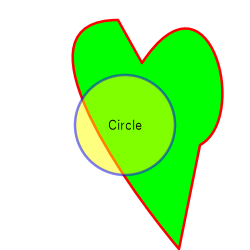

In [28]:
from io import BytesIO
from IPython.display import display_png

png_buf = BytesIO()
plt.imsave(png_buf, arr, format="png")
display_png(png_buf.getvalue(), raw=True)

この本では、画像の上に描くための `ImageDrawer` を用意しています。次の例では、画像の上にマーカー、文字、直線、円、長方形、楕円を描き、`%array_image` マジックで表示します。

`ImageDrawer` の `reverse` は y 軸の向きです。既定は `True` で、y が下向きになり、画像のピクセルの座標と同じです。`False` にすると y が上向きになり、数学の座標と同じです。

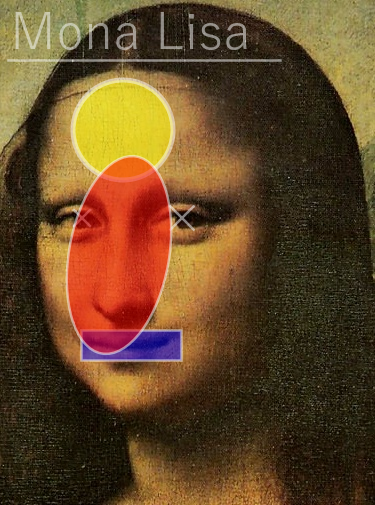

In [29]:
from helper.matplotlib import ImageDrawer
from helper.numpy import array_image

img = plt.imread("data/vinci_target.png")
drawer = ImageDrawer(img)
drawer.set_parameters(lw=2, color="white", alpha=0.5)
drawer.line(8, 60, 280, 60)
drawer.circle(123, 130, 50, facecolor="yellow", lw=4)
drawer.markers("x", [82, 182], [218, 218], [50, 100])
drawer.rectangle(81, 330, 100, 30, facecolor="blue")
drawer.text(10, 50, "Mona Lisa", fontsize=40)
drawer.ellipse(119, 255, 200, 100, 100, facecolor="red")
array_image(drawer.to_array())

### アニメーション

部品の属性を変えて描き直すと、簡単なアニメーションになります。次の例では、次のようにします。

❶ 50 ミリ秒のタイマーを作り、`add_callback()` で関数を登録します。第 1 引数が呼ぶ関数、第 2 引数がその関数に渡すものです。曲線のデータを変えるので、`Line2D` の `line` を渡します。❷ `set_ydata()` で y のデータを変えます。❸ `canvas.draw()` で図全体を描き直します。

:::{tip}
JupyterLab で対話的に動かすには、`ipympl` を入れて、セルで次のマジックを実行します。

```bash
pip install ipympl
```

```python
%matplotlib ipympl
```
:::

In [30]:
%matplotlib ipympl

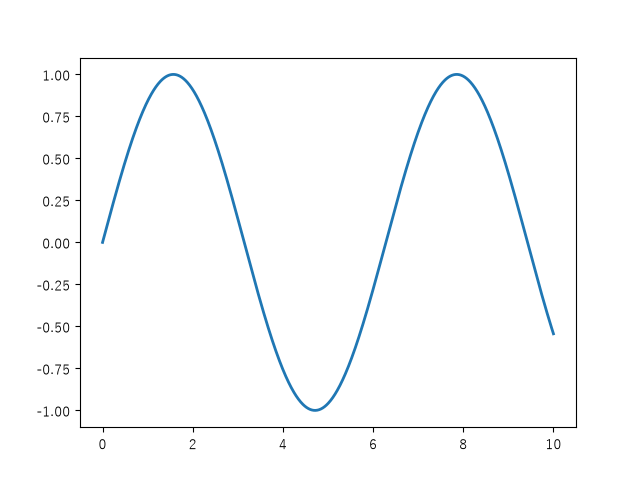

In [31]:
from matplotlib import pyplot as plt
import numpy as np

fig, ax = plt.subplots()
x = np.linspace(0, 10, 1000)
(line,) = ax.plot(x, np.sin(x), lw=2)


def update_data(line):
    x[:] += 0.1
    line.set_ydata(np.sin(x))  #❷
    fig.canvas.draw()  #❸


timer = fig.canvas.new_timer(interval=50)  #❶
timer.add_callback(update_data, line)
timer.start()

タイマーは次のコードで止めます。

In [32]:
timer.stop()

#### キャッシュで速く描き直す

`canvas.draw()` は遅いので、動かない部分をそのまま使い、動く部分だけを描き直すと速くなります。次の例では、次のようにします。

❶ 部品を作るときに `animated=True` にします。❷ `canvas.draw()` では、`animated` が `True` のものは描かれません。❸ 静的な部分を描いたら、`copy_from_bbox()` でサブプロットの領域の画像を `background` に保存します。位置と大きさは `bbox` から取れます。

タイマーの関数では、❹ `restore_region()` で保存した画像に戻します。動く部分を消して、静的な部分を描き直すのと同じです。❺ y のデータを変えてから `draw_artist()` で曲線を画布に描きます。❻ `blit()` で、画布のその領域を画面に出します。

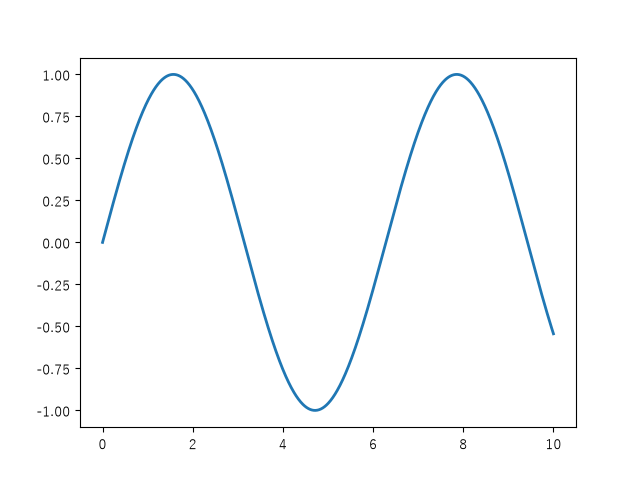

In [33]:
fig, ax = plt.subplots()
x = np.linspace(0, 10, 1000)
(line,) = ax.plot(x, np.sin(x), lw=2, animated=True)  #❶

fig.canvas.draw()  #❷
background = fig.canvas.copy_from_bbox(ax.bbox)  #❸


def update_data(line):
    x[:] += 0.1
    line.set_ydata(np.sin(x))
    fig.canvas.restore_region(background)  #❹
    ax.draw_artist(line)  #❺
    fig.canvas.blit(ax.bbox)  #❻


timer = fig.canvas.new_timer(interval=50)
timer.add_callback(update_data, line)
timer.start()

In [34]:
timer.stop()

#### `animation` モジュール

ここまでの 2 つの例で仕組みは分かりましたが、ふつうは `animation` モジュールを使います。`FuncAnimation` は、決まった間隔で関数を呼び、図の部品を更新します。

❶ 曲線を作るときに `animated=True` にします。❷ 更新の関数 `update_line()` で、動く部品のデータを入れます。引数にフレームの番号が渡るので、それで位相を変え、動く部品の並びを返します。❸ `FuncAnimation` を作り、`update_line()` を定期的に呼びます。`interval` は 1 フレームのミリ秒、`blit=True` でキャッシュを使って速くし、`frames` がフレームの数です。

In [35]:
%matplotlib inline

In [36]:
from matplotlib.animation import FuncAnimation

plt.ioff()
fig, ax = plt.subplots()

x = np.linspace(0, 4 * np.pi, 200)
y = np.sin(x)
(line,) = ax.plot(x, y, lw=2, animated=True)  #❶


def update_line(i):
    y = np.sin(x + i * 2 * np.pi / 100)
    line.set_ydata(y)
    return [line]  #❷


ani = FuncAnimation(fig, update_line, blit=True, interval=25, frames=100)  #❸

動画として保存するには、次のように呼びます。

:::{warning}
matplotlib は、システムに入っている動画の圧縮ソフト(`ffmpeg.exe` など)で動画を作ります。実行ファイルのあるフォルダが `PATH` に入っているか確かめてください。
:::

In [37]:
ani.save("sin_wave.mp4", fps=25)

できたアニメーションが次です。

In [38]:
from IPython.display import Video

Video("sin_wave.mp4", embed=True)

## まとめ

* 図には 4 つの座標系がある。データ、サブプロット、図、ウィンドウ。
* `transData`、`transAxes`、`transFigure` で座標をウィンドウ座標に変えられる。`inverted()` で逆も取れる。
* x と y で別の座標系を使うときは `blended_transform_factory()` で混ぜる。
* `transData` は `transScale` + `transLimits` + `transAxes`。対数軸では `transScale` が働く。
* 文字は `text()`(データ座標)と `figtext()`(図座標)、矢印付きは `annotate()`。`xycoords` と `textcoords` で座標系を決める。
* `RendererAgg` で、図を使わずに 2 次元の絵を描いて配列にできる。
* アニメーションは、タイマーでデータを変えて描き直す。速くするときは `animated` と `blit` を使う。ふつうは `FuncAnimation` を使う。